# Scanning a velocity selector

How does the rotation speed of a velocity selector affect the neutron beam? Inspired by the [diagnostics tutorial](McStasScript_tutorial_6_Diagnostics.ipynb), we will send a broad wavelength distribution through a guide and velocity selector, then scan its speed. We will compare both the integrated transmitted intensity and the wavelength spectra. This is a simplified instrument for exploring the scan API, not a calibrated selector model.

You need McStasScript with scan execution and stacking support, **McStas 3.10.0**, a C compiler, and a Jupyter kernel using that McStas installation. Run all cells in order. Each point simulates the same configured number of neutron histories; the whole scan takes longer than one point.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import mcstasscript as ms

## Choose a new output name

Scan roots are never reused or overwritten. Change `run_name` before rerunning this notebook, or choose another location. The instrument's run directory and the scan output root are separate; the latter must not exist yet.

In [2]:
run_name = 'selector_speed_scan'
run_path = (Path('run_folder') / run_name).resolve()
scan_path = (Path('data_folder') / run_name).resolve()
if scan_path.exists():
    raise FileExistsError(f'{scan_path} exists; choose a new run_name.')
run_path.mkdir(parents=True, exist_ok=True)
scan_path.parent.mkdir(parents=True, exist_ok=True)

## Build the instrument

As in the diagnostics example, a `Source_simple` illuminates a `Guide_gravity` and a `V_selector`. A wavelength monitor after the selector measures the transmitted beam. The instrument parameter `selector_speed` controls `nu` in the selector component. The source covers 3–6 Å, so changing the speed can move the transmitted band through that range.

In [3]:
instrument = ms.McStas_instr('selector_scan_demo', input_path=str(run_path))
speed = instrument.add_parameter('selector_speed', value=370.0,
                                 comment='Selector rotation frequency [Hz]')
source = instrument.add_component('source', 'Source_simple')
source.set_parameters(xwidth=0.1, yheight=0.1, focus_xw=0.04,
                      focus_yh=0.06, dist=2, flux=1e7,
                      lambda0=4.5, dlambda=1.5)
guide = instrument.add_component('guide', 'Guide_gravity')
guide.set_parameters(w1=0.04, h1=0.06, m=2, G=-9.82, l=10)
guide.set_AT([0, 0, 2], RELATIVE=source)
selector = instrument.add_component('selector', 'V_selector')
selector.set_parameters(xwidth=0.04, yheight=0.06, zdepth=0.4,
                        radius=0.15, length=0.3, nu=speed)
selector.set_AT([0, 0, 10.200001], RELATIVE=guide)
spectrum = instrument.add_component('spectrum', 'L_monitor')
spectrum.set_parameters(xwidth=0.08, yheight=0.1, nL=60,
                        Lmin=3, Lmax=6, filename='"spectrum.dat"')
spectrum.set_AT([0, 0, 0.21], RELATIVE=selector)

## Plan, check, and run

A grid with one axis requests each speed once. Set the instrument's run settings **before** scanning: `ncount` is per point, not the total for the scan. The seed makes this example reproducible under the same verified native configuration. Preflight validates the request without compiling or running it.

`instrument.scan(plan)` writes an isolated copy of the instrument and a manifest in the new scan root. The original instrument and its settings remain unchanged.

In [4]:
plan = ms.ScanPlan.grid(selector_speed=[260, 310, 370, 430, 490])
instrument.settings(output_path=str(scan_path), ncount=200_000,
                    seed=314159, NeXus=False)
report = instrument.scan_preflight(plan)
print('Preflight valid:', report.valid)
print('Warnings:', report.warnings)
if not report.valid:
    raise RuntimeError(report.errors)
scan = instrument.scan(plan)
print('Scan output name:', scan_path.name)
print('Point count:', len(scan.points))
assert len(scan.points) == 5

Preflight valid: True
Warnings: ()


Scan output name: selector_speed_scan
Point count: 5


## Inspect integrated transmission

The monitor view contains one scalar intensity and uncertainty per requested point. Inspect validity before using a value. The overview plot reads summaries without loading the full detector histograms. The native process exit status does not by itself prove individual point success; point execution status can remain `unknown` even when data is readable.

0: 260 Hz, intensity=451.9, valid=True, status=unknown
1: 310 Hz, intensity=1.059e+05, valid=True, status=unknown
2: 370 Hz, intensity=8.093e+04, valid=True, status=unknown
3: 430 Hz, intensity=5.598e+04, valid=True, status=unknown
4: 490 Hz, intensity=3.985e+04, valid=True, status=unknown


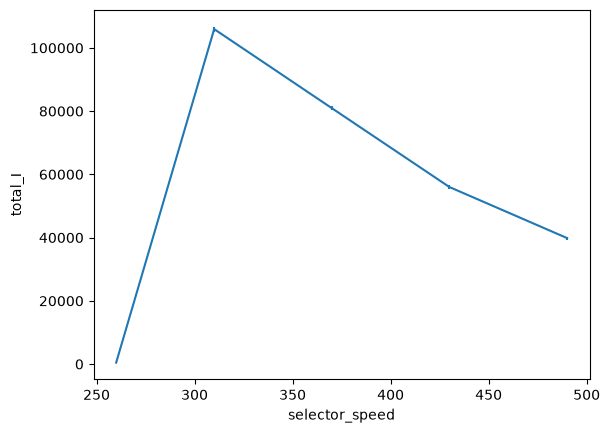

In [5]:
view = scan.dataset('spectrum')
assert view.valid.all()
for point, intensity, valid in zip(scan.points, view.total_I, view.valid):
    print(f'{point.point_id}: {point.parameters["selector_speed"]} Hz, '
          f'intensity={intensity:.4g}, valid={valid}, status={point.status}')
scan.plot_overview(monitor='spectrum', x='selector_speed', show=False)
plt.show()

## Compare the wavelength spectra

An integrated intensity cannot show where the selector transmits. `stack()` explicitly loads the binned monitor at every available point, checks that the binning and metadata agree, and returns arrays with scan dimensions followed by detector dimensions. It does not rebin. Missing or unavailable values are NaN and have false validity masks. The optional memory limit applies to the estimated output arrays, not to already loaded source data.

Dimensions: ('selector_speed', 'detector_x') shape: (5, 60)


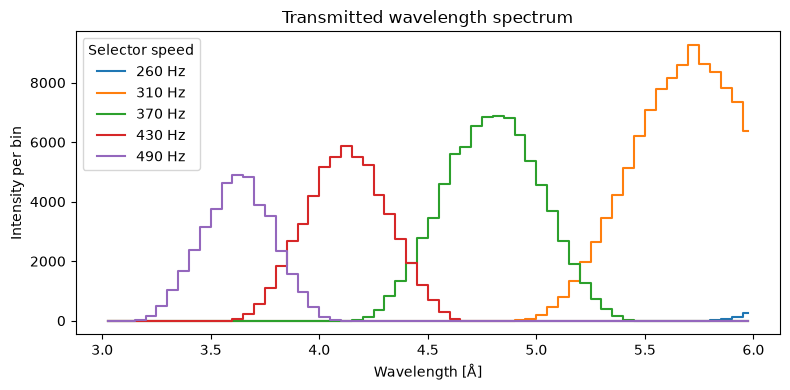

In [6]:
stacked = view.stack(max_bytes=10_000_000)
assert stacked.Intensity.shape == (5, 60)
assert stacked.validity['Intensity'].all()
print('Dimensions:', stacked.dims, 'shape:', stacked.Intensity.shape)
wavelength = stacked.coordinates['detector_x']
fig, ax = plt.subplots(figsize=(8, 4))
for i, speed_value in enumerate(stacked.coordinates['selector_speed']):
    values = np.where(stacked.validity['Intensity'][i], stacked.Intensity[i], np.nan)
    ax.step(wavelength, values, where='mid', label=f'{speed_value} Hz')
ax.set(xlabel='Wavelength [Å]', ylabel='Intensity per bin',
       title='Transmitted wavelength spectrum')
ax.legend(title='Selector speed')
fig.tight_layout()
plt.show()

Compare the position and height of the bands. The finite source range, guide transmission and Monte Carlo noise all affect the measured spectra: an edge speed may transmit little intensity, and the integrated intensity alone does not explain why. Try more histories or different speeds with a **new** output name before drawing a physical conclusion.

Individual original detector datasets remain available via `scan.points[i].data.find('spectrum')`. Stacking is intended for compatible binned monitors, not event lists.

## Reload and inspect partial results

The manifest records the requested plan, so a later session can reload the scan without rerunning it. Requested points remain represented even if some output is missing. For longer scans, `on_error='continue'` can return partial results; with the default `on_error='raise'`, catch `ms.ScanExecutionError` and inspect its `.result`. Neither option silently retries simulations.

In [7]:
reloaded = ms.load_scan(scan_path)
print('Reloaded points:', len(reloaded.points))
print('Data status:', [point.data_status for point in reloaded.points])
print('Integrated intensities:', reloaded.dataset('spectrum').total_I)
np.testing.assert_allclose(reloaded.dataset('spectrum').total_I, view.total_I)

Reloaded points: 5
Data status: ['available', 'available', 'available', 'available', 'available']
Integrated intensities: [   451.861 105936.     80933.4    55984.6    39848.7  ]


For other scan layouts, see the [scan plan guide](../user_guide/scan_plans.rst); for execution limitations and output layout, see [scan execution](../user_guide/scan_execution.rst). [Tutorial 7](McStasScript_tutorial_7_native_scans.ipynb) shows loading scans run outside McStasScript, and [tutorial 8](McStasScript_tutorial_8_scan_analysis.ipynb) focuses on summary analysis.